In [1]:
!pip install -q tensorflow scikit-learn seaborn matplotlib pandas numpy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("First review sequence:", x_train[0][:20])
print("First review label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
First review sequence: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label: 1


In [4]:
x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [5]:
def create_rnn_model():
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
        SimpleRNN(64),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def create_lstm_model():
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
        LSTM(64),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def create_gru_model():
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
        GRU(64),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [6]:
rnn_model = create_rnn_model()
lstm_model = create_lstm_model()
gru_model = create_gru_model()

print("RNN MODEL")
rnn_model.summary()

print("\nLSTM MODEL")
lstm_model.summary()

print("\nGRU MODEL")
gru_model.summary()

RNN MODEL


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

...

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
epochs = 5
batch_size = 128

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

histories = {}
training_times = {}

for name, model in models.items():
    print(f"\nTraining {name} Model...")

    start_time = time.time()

    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=[early_stopping],
        verbose=1
    )

    end_time = time.time()

    histories[name] = history
    training_times[name] = end_time - start_time

    print(f"{name} Training Time: {training_times[name]:.2f} seconds")


Training RNN Model...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - accuracy: 0.5045 - loss: 0.7001 - val_accuracy: 0.5012 - val_loss: 0.6945
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - accuracy: 0.5756 - loss: 0.6741 - val_accuracy: 0.5226 - val_loss: 0.6897
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 125ms/step - accuracy: 0.6324 - loss: 0.6313 - val_accuracy: 0.5054 - val_loss: 0.7094
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.7016 - loss: 0.5175 - val_accuracy: 0.5248 - val_loss: 0.7582
RNN Training Time: 79.87 seconds

Training LSTM Model...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 364ms/step - accuracy: 0.5265 - loss: 0.6905 - val_accuracy: 0.5936 - val_loss: 0.6617
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 358ms/step - accuracy: 0.6163 - loss: 0.6649 - val_accuracy: 0.6490 - val_loss: 0.6239
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 358ms/step - accuracy: 0.7388 - loss: 0.5429 - val_accuracy: 0.7478 - val_loss: 0.5432
Epoch 4/5


In [8]:
results = []

predictions = {}

for name, model in models.items():
    print(f"\nEvaluating {name} Model...")

    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    y_prob = model.predict(x_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (sec)": training_times[name]
    })

results_df = pd.DataFrame(results)

print("\nModel Performance Comparison:")
display(results_df.round(4))


Evaluating RNN Model...

Evaluating LSTM Model...

Evaluating GRU Model...

Model Performance Comparison:


,Model,Test Loss,Accuracy,Precision,Recall,F1-Score,Training Time (sec)
0,RNN,0.6899,0.5246,0.5181,0.7057,0.5975,79.8699
1,LSTM,0.5197,0.7766,0.7718,0.7854,0.7786,288.5736
2,GRU,0.6917,0.5170,0.5367,0.2484,0.3396,166.4527


In [9]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 50)
    print(f"{name} CLASSIFICATION REPORT")
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))


RNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.54      0.34      0.42     12500
    Positive       0.52      0.71      0.60     12500

    accuracy                           0.52     25000
   macro avg       0.53      0.52      0.51     25000
weighted avg       0.53      0.52      0.51     25000


LSTM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.78      0.77      0.77     12500
    Positive       0.77      0.79      0.78     12500

    accuracy                           0.78     25000
   macro avg       0.78      0.78      0.78     25000
weighted avg       0.78      0.78      0.78     25000


GRU CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.51      0.79      0.62     12500
    Positive       0.54      0.25      0.34     12500

    accuracy                           0.52     25000
   macro avg       0.52      0.52      0.48   

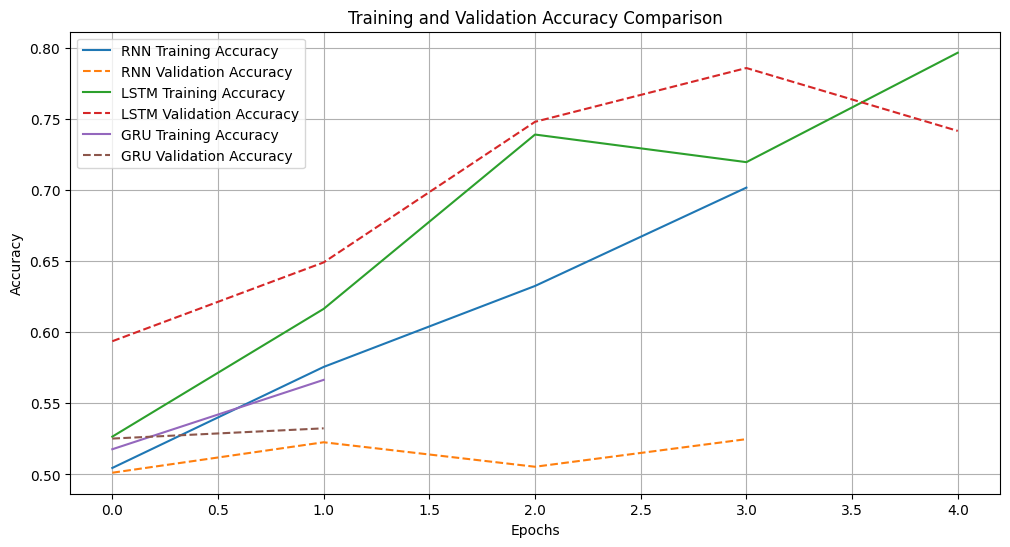

In [10]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history.history['accuracy'],
        label=f'{name} Training Accuracy'
    )
    plt.plot(
        history.history['val_accuracy'],
        linestyle='--',
        label=f'{name} Validation Accuracy'
    )

plt.title("Training and Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

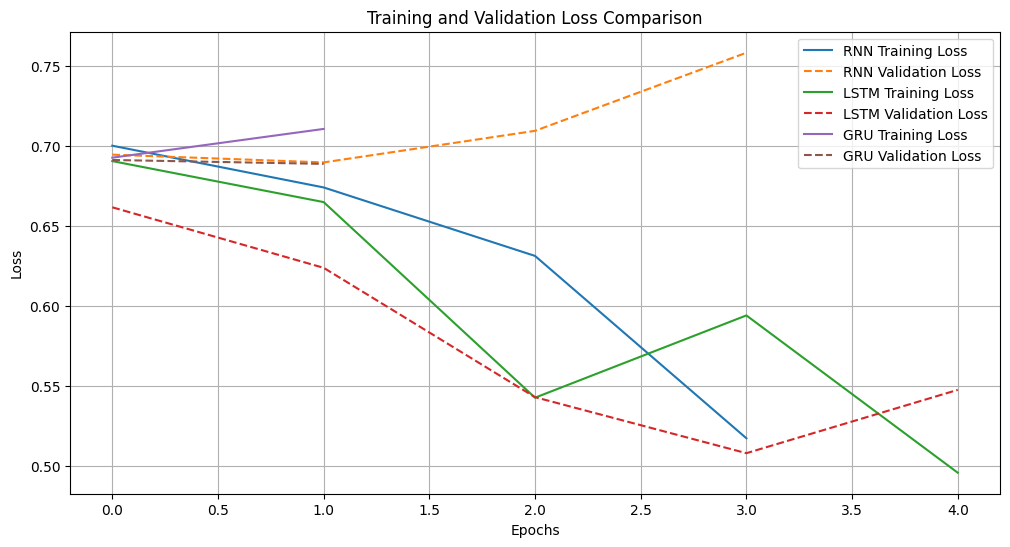

In [11]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history.history['loss'],
        label=f'{name} Training Loss'
    )
    plt.plot(
        history.history['val_loss'],
        linestyle='--',
        label=f'{name} Validation Loss'
    )

plt.title("Training and Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

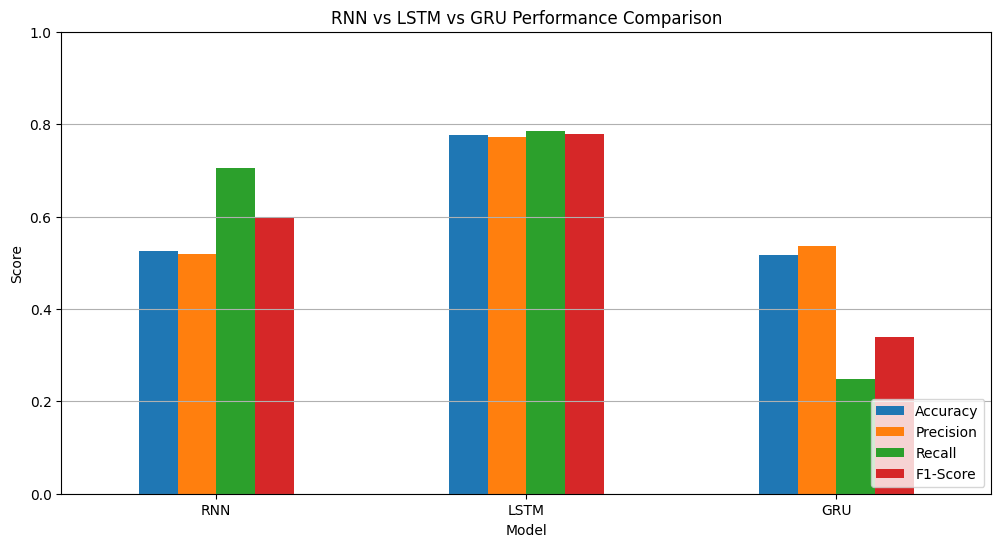

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

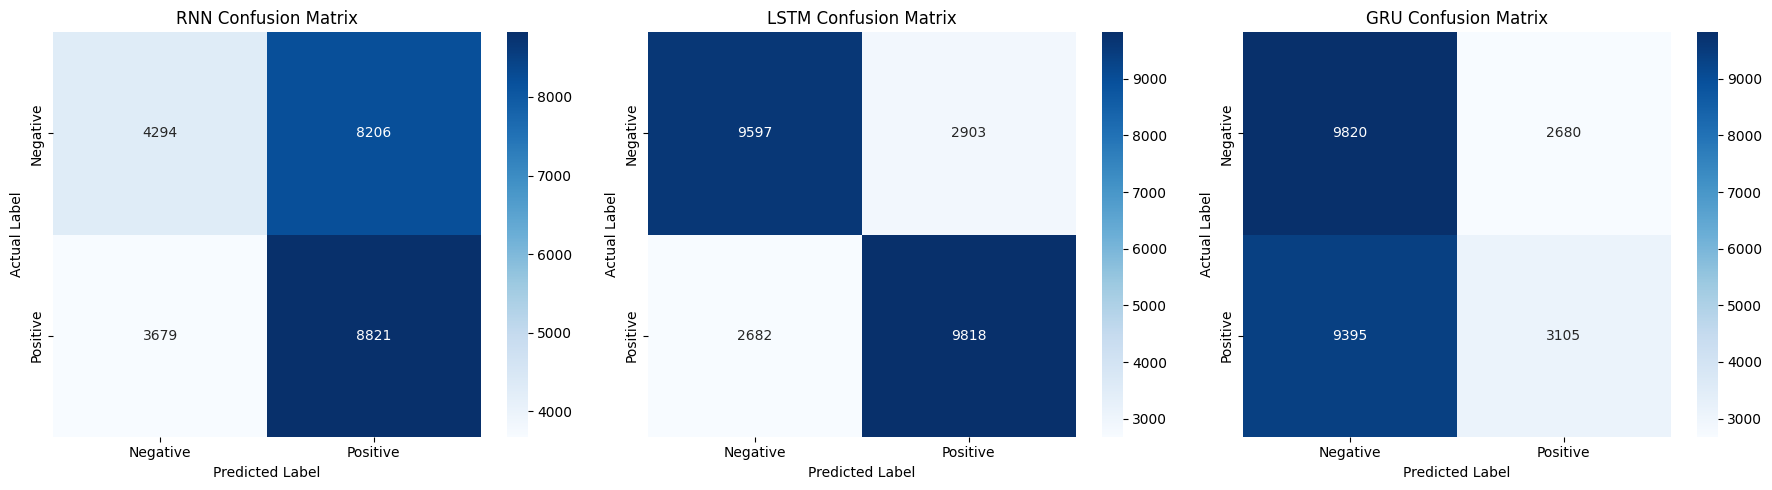

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

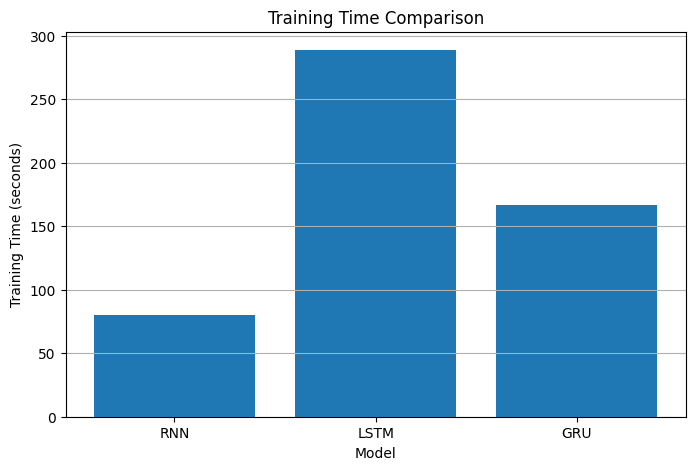

Training Time Comparison:


,Model,Training Time (sec)
0,RNN,79.87
1,LSTM,288.57
2,GRU,166.45


In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Training Time (sec)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.grid(axis='y')
plt.show()

print("Training Time Comparison:")
display(results_df[["Model", "Training Time (sec)"]].round(2))

In [15]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best Model Based on F1-Score:")
print(best_model)

Best Model Based on F1-Score:
Model                        LSTM
Test Loss                0.519738
Accuracy                   0.7766
Precision                0.771795
Recall                    0.78544
F1-Score                 0.778558
Training Time (sec)    288.573562
Name: 1, dtype: object


In [16]:
word_index = imdb.get_word_index()

def encode_review(review):
    words = review.lower().split()

    encoded = [
        word_index.get(word, 2) + 3
        for word in words
    ]

    return pad_sequences(
        [encoded],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

custom_review = "This movie was excellent and I really enjoyed it"

encoded_review = encode_review(custom_review)

print("Custom Review:", custom_review)

for name, model in models.items():
    probability = model.predict(encoded_review, verbose=0)[0][0]
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print(
        f"{name}: {sentiment} "
        f"(Probability: {probability:.4f})"
    )

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Custom Review: This movie was excellent and I really enjoyed it
RNN: Positive (Probability: 0.5138)
LSTM: Positive (Probability: 0.8098)
GRU: Negative (Probability: 0.4826)
